# NoSQL & Modern Data Stores — Right Tool for the Right Job

## Why SQL Isn't Always the Answer

Relational databases are excellent — but ML systems push them to their limits:

- **Variable schemas**: Experiment configs have different hyperparameters per run — a fixed schema can't represent this cleanly
- **Massive write throughput**: Logging 1M feature events/second overwhelms ACID transactions
- **Unstructured data**: Model cards, raw text, JSON predictions don't fit neatly into rows and columns
- **Scale-out requirements**: SQL scales *up* (bigger machine); NoSQL scales *out* (more machines)

> **Key insight**: There is no single best database. Real ML systems use **polyglot persistence** — 3-4 different stores simultaneously, each chosen for what it does best.

/tmp/ipykernel_186280/3914387056.py:52: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_186280/3914387056.py:52: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_186280/3914387056.py:52: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_186280/3914387056.py:53: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) DejaVu Sans.
  plt.savefig('nosql_landscape.png', dpi=120, bbox_inches='tight')
/tmp/ipykernel_186280/3914387056.py:53: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  plt.savefig('nosql_landscape.png', dpi=120, bbox_inches='tight')
/tmp/ipykernel_186280/3914387056.py:53: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.savefig('nosql_landscape.png', dpi=120, bbox_inches='tight')


.../site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
.../site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
.../site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


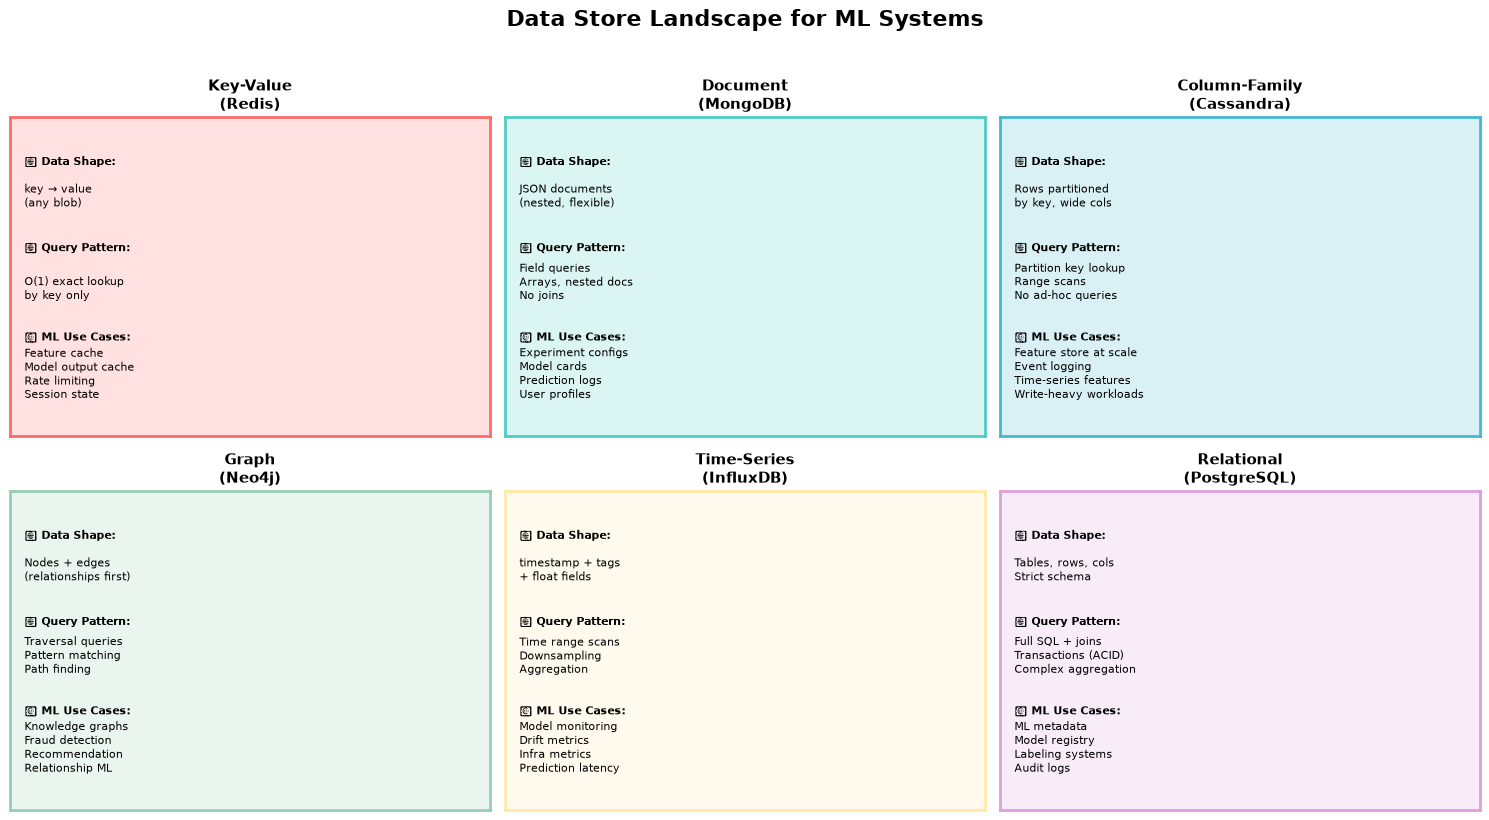

Data store landscape: 6 types, each optimized for a different access pattern


In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Data Store Landscape for ML Systems', fontsize=16, fontweight='bold', y=1.02)

stores = [
    {'name': 'Key-Value\n(Redis)', 'color': '#FF6B6B',
     'data_shape': 'key → value\n(any blob)',
     'query': 'O(1) exact lookup\nby key only',
     'ml_use': 'Feature cache\nModel output cache\nRate limiting\nSession state'},
    {'name': 'Document\n(MongoDB)', 'color': '#4ECDC4',
     'data_shape': 'JSON documents\n(nested, flexible)',
     'query': 'Field queries\nArrays, nested docs\nNo joins',
     'ml_use': 'Experiment configs\nModel cards\nPrediction logs\nUser profiles'},
    {'name': 'Column-Family\n(Cassandra)', 'color': '#45B7D1',
     'data_shape': 'Rows partitioned\nby key, wide cols',
     'query': 'Partition key lookup\nRange scans\nNo ad-hoc queries',
     'ml_use': 'Feature store at scale\nEvent logging\nTime-series features\nWrite-heavy workloads'},
    {'name': 'Graph\n(Neo4j)', 'color': '#96CEB4',
     'data_shape': 'Nodes + edges\n(relationships first)',
     'query': 'Traversal queries\nPattern matching\nPath finding',
     'ml_use': 'Knowledge graphs\nFraud detection\nRecommendation\nRelationship ML'},
    {'name': 'Time-Series\n(InfluxDB)', 'color': '#FFEAA7',
     'data_shape': 'timestamp + tags\n+ float fields',
     'query': 'Time range scans\nDownsampling\nAggregation',
     'ml_use': 'Model monitoring\nDrift metrics\nInfra metrics\nPrediction latency'},
    {'name': 'Relational\n(PostgreSQL)', 'color': '#DDA0DD',
     'data_shape': 'Tables, rows, cols\nStrict schema',
     'query': 'Full SQL + joins\nTransactions (ACID)\nComplex aggregation',
     'ml_use': 'ML metadata\nModel registry\nLabeling systems\nAudit logs'},
]

for ax, store in zip(axes.flat, stores):
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.set_facecolor(store['color'] + '33')
    ax.set_title(store['name'], fontweight='bold', fontsize=11)
    ax.text(0.3, 8.5, '📦 Data Shape:', fontsize=8, fontweight='bold')
    ax.text(0.3, 7.2, store['data_shape'], fontsize=8)
    ax.text(0.3, 5.8, '🔍 Query Pattern:', fontsize=8, fontweight='bold')
    ax.text(0.3, 4.3, store['query'], fontsize=8)
    ax.text(0.3, 3.0, '🤖 ML Use Cases:', fontsize=8, fontweight='bold')
    ax.text(0.3, 1.2, store['ml_use'], fontsize=8)
    for spine in ax.spines.values():
        spine.set_linewidth(2)
        spine.set_edgecolor(store['color'])
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig('nosql_landscape.png', dpi=120, bbox_inches='tight')
plt.show()
print('Data store landscape: 6 types, each optimized for a different access pattern')

## Key-Value Stores (Redis)

**Core idea**: A giant hash map in RAM. Every value stored behind a single key.

| Property | Detail |
|----------|--------|
| Lookup time | O(1) — constant regardless of dataset size |
| Storage | In-memory (optionally persisted to disk) |
| TTL support | Keys expire automatically after N seconds |
| Data types | Strings, lists, sets, sorted sets, hashes, streams |
| Tradeoff | Memory-bound; no joins; no complex queries |

**Why ML engineers care**: Feature serving latency must be <10ms. Redis sits between your feature store (slow) and your model server (needs features now). It's the **hot cache** for the features your model needs at inference time.

In [2]:
import time
import hashlib
import json
from datetime import datetime

# ── Mock Redis using a Python dict ──────────────────────────────────────────
class MockRedis:
    """Simulates Redis behavior: TTL, get/set, incr."""
    def __init__(self):
        self._store = {}   # key → (value, expire_at)

    def set(self, key, value, ex=None):
        expire_at = time.time() + ex if ex else None
        self._store[key] = (value, expire_at)

    def get(self, key):
        if key not in self._store:
            return None
        value, expire_at = self._store[key]
        if expire_at and time.time() > expire_at:
            del self._store[key]
            return None          # TTL expired
        return value

    def incr(self, key):
        val = int(self.get(key) or 0) + 1
        self.set(key, str(val))
        return val

redis = MockRedis()

# ── Pattern 1: Feature Cache ──────────────────────────────────────────────────
def get_user_features(user_id: str, redis: MockRedis) -> dict:
    cache_key = f"features:{user_id}"
    cached = redis.get(cache_key)
    if cached:
        print(f"  CACHE HIT  → {cache_key}")
        return json.loads(cached)
    # Simulate slow feature store lookup
    features = {"age": 28, "spend_30d": 142.5, "clicks_7d": 23}
    redis.set(cache_key, json.dumps(features), ex=300)  # cache for 5 min
    print(f"  CACHE MISS → fetched from feature store, cached for 300s")
    return features

print("=== Pattern 1: Feature Cache ===")
get_user_features("user_123", redis)   # miss
get_user_features("user_123", redis)   # hit

# ── Pattern 2: Model Output Cache (Idempotent Predictions) ────────────────────
def predict_with_cache(input_data: dict, redis: MockRedis) -> float:
    cache_key = "pred:" + hashlib.md5(json.dumps(input_data, sort_keys=True).encode()).hexdigest()[:8]
    cached = redis.get(cache_key)
    if cached:
        print(f"  Prediction cache hit → {float(cached):.4f}")
        return float(cached)
    prediction = 0.87   # simulate model inference
    redis.set(cache_key, str(prediction), ex=3600)  # cache 1 hour
    print(f"  Model inference ran → {prediction:.4f} (cached)")
    return prediction

print("\n=== Pattern 2: Prediction Cache ===")
predict_with_cache({"user_id": "u1", "item_id": "i99"}, redis)  # miss
predict_with_cache({"user_id": "u1", "item_id": "i99"}, redis)  # hit

# ── Pattern 3: Rate Limiter ───────────────────────────────────────────────────
def check_rate_limit(user_id: str, redis: MockRedis, limit=5) -> bool:
    key = f"ratelimit:{user_id}:{int(time.time() // 60)}"
    count = redis.incr(key)
    if count == 1:
        redis.set(key, "1", ex=60)   # expire after 1 minute
    return count <= limit

print("\n=== Pattern 3: Rate Limiter ===")
for i in range(7):
    allowed = check_rate_limit("user_42", redis, limit=5)
    print(f"  Request {i+1}: {'✅ allowed' if allowed else '❌ rate limited'}")

=== Pattern 1: Feature Cache ===
  CACHE MISS → fetched from feature store, cached for 300s
  CACHE HIT  → features:user_123

=== Pattern 2: Prediction Cache ===
  Model inference ran → 0.8700 (cached)
  Prediction cache hit → 0.8700

=== Pattern 3: Rate Limiter ===
  Request 1: ✅ allowed
  Request 2: ✅ allowed
  Request 3: ✅ allowed
  Request 4: ✅ allowed
  Request 5: ✅ allowed
  Request 6: ❌ rate limited
  Request 7: ❌ rate limited


## Document Stores (MongoDB)

**Core idea**: Store JSON-like documents. No fixed schema — different documents in the same collection can have different fields.

```json
// Experiment run 1 — Random Forest
{ "run_id": "a1b2", "model": "random_forest", "n_estimators": 100, "max_depth": 5, "accuracy": 0.91 }

// Experiment run 2 — Neural Network (different hyperparams!)
{ "run_id": "c3d4", "model": "mlp", "layers": [128, 64], "lr": 0.001, "dropout": 0.3, "accuracy": 0.93 }
```

Both live in the same `experiments` collection. SQL would force you to either create nullable columns for every possible hyperparameter, or use an EAV table (slow, ugly).

**ML use cases**: Experiment tracking, model cards, storing predictions with variable metadata, user event logs.

**Tradeoffs**:
- ❌ No joins (denormalize your data, accept redundancy)
- ❌ Eventual consistency (by default — tunable)
- ✅ Horizontal sharding built-in
- ✅ Native JSON, no ORM needed

## Column-Family Stores (Cassandra)

**Core idea**: Data is partitioned by a key across nodes. Optimized for **write throughput** — designed around how you query, not how data is normalized.

```sql
-- Cassandra table for a feature store
CREATE TABLE user_features (
    user_id   TEXT,
    feature   TEXT,
    value     FLOAT,
    updated   TIMESTAMP,
    PRIMARY KEY (user_id, feature)
);
-- Designed for: SELECT * WHERE user_id = ? (fast partition lookup)
-- NOT designed for: SELECT * WHERE value > 0.5 (full scan, slow)
```

**Rule**: Design your Cassandra schema around your **query patterns**, not entity relationships. Write the queries first, then the schema.

**ML use cases**: Feature stores at scale (Uber Michelangelo, Netflix), event streams, time-series feature logging.

/tmp/ipykernel_186280/662255595.py:59: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_186280/662255595.py:60: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.savefig('db_decision_guide.png', dpi=120, bbox_inches='tight')


.../site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


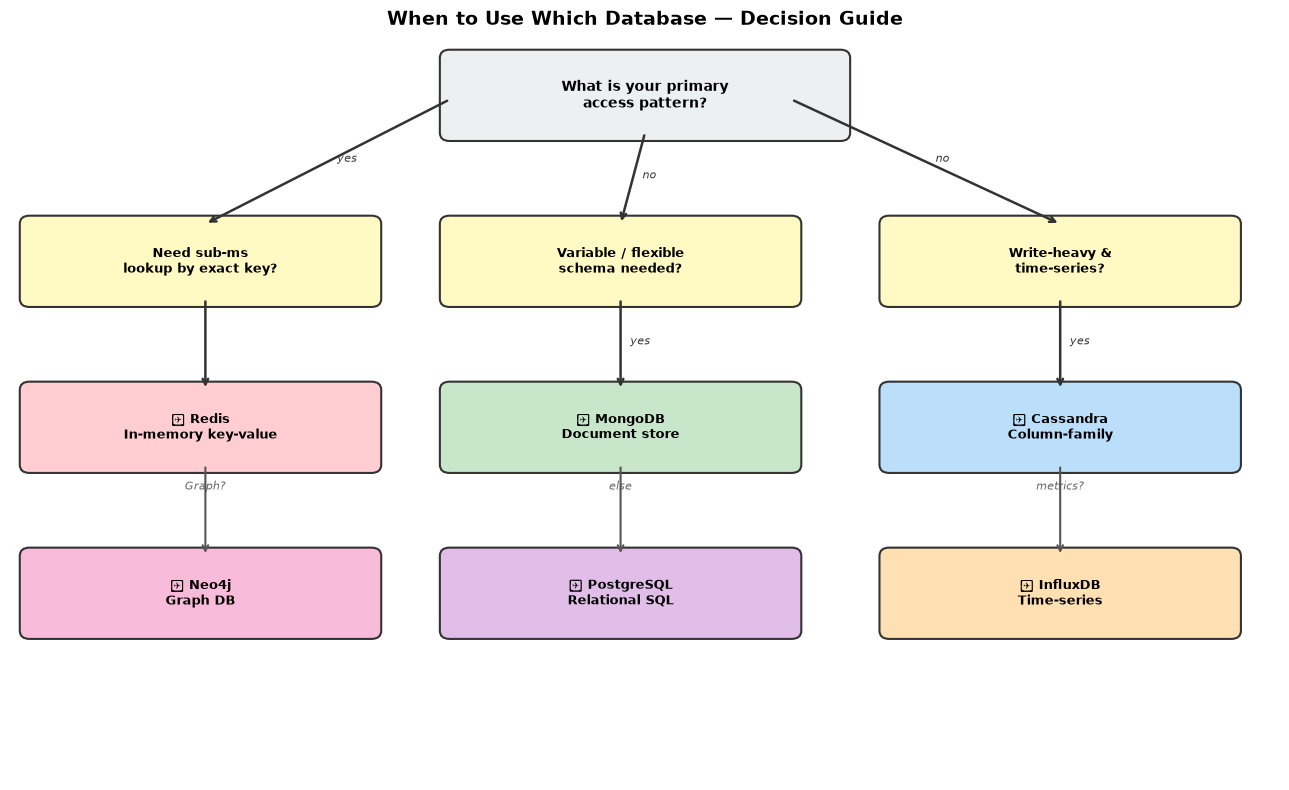

Rule: choose by ACCESS PATTERN, not familiarity.


In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(13, 8))
ax.set_xlim(0, 13)
ax.set_ylim(0, 9)
ax.axis('off')
ax.set_title('When to Use Which Database — Decision Guide', fontsize=14, fontweight='bold')

def box(ax, x, y, w, h, text, color, fontsize=9):
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.1',
                                    facecolor=color, edgecolor='#333', linewidth=1.5)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center',
            fontsize=fontsize, fontweight='bold', wrap=True,
            multialignment='center')

def arrow(ax, x1, y1, x2, y2, label='', color='#333'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.8))
    if label:
        mx, my = (x1+x2)/2, (y1+y2)/2
        ax.text(mx+0.1, my, label, fontsize=8, color=color, style='italic')

# Start
box(ax, 4.5, 7.8, 4, 0.9, 'What is your primary\naccess pattern?', '#ECF0F1', 10)

# Branch 1: Sub-ms lookup
box(ax, 0.2, 5.8, 3.5, 0.9, 'Need sub-ms\nlookup by exact key?', '#FFF9C4', 9)
box(ax, 0.2, 3.8, 3.5, 0.9, '✅ Redis\nIn-memory key-value', '#FFCDD2', 9)
arrow(ax, 4.5, 8.2, 2.0, 6.7, 'yes')
arrow(ax, 2.0, 5.8, 2.0, 4.7)

# Branch 2: Variable schema
box(ax, 4.5, 5.8, 3.5, 0.9, 'Variable / flexible\nschema needed?', '#FFF9C4', 9)
box(ax, 4.5, 3.8, 3.5, 0.9, '✅ MongoDB\nDocument store', '#C8E6C9', 9)
arrow(ax, 6.5, 7.8, 6.25, 6.7, 'no')
arrow(ax, 6.25, 5.8, 6.25, 4.7, 'yes')

# Branch 3: Write-heavy
box(ax, 9.0, 5.8, 3.5, 0.9, 'Write-heavy &\ntime-series?', '#FFF9C4', 9)
box(ax, 9.0, 3.8, 3.5, 0.9, '✅ Cassandra\nColumn-family', '#BBDEFB', 9)
arrow(ax, 8.0, 8.2, 10.75, 6.7, 'no')
arrow(ax, 10.75, 5.8, 10.75, 4.7, 'yes')

# Branch 4: Graph vs Relational
box(ax, 0.2, 1.8, 3.5, 0.9, '✅ Neo4j\nGraph DB', '#F8BBD9', 9)
box(ax, 4.5, 1.8, 3.5, 0.9, '✅ PostgreSQL\nRelational SQL', '#E1BEE7', 9)
box(ax, 9.0, 1.8, 3.5, 0.9, '✅ InfluxDB\nTime-series', '#FFE0B2', 9)

ax.text(2.0, 3.5, 'Graph?', fontsize=8, ha='center', style='italic', color='#666')
ax.text(6.25, 3.5, 'else', fontsize=8, ha='center', style='italic', color='#666')
ax.text(10.75, 3.5, 'metrics?', fontsize=8, ha='center', style='italic', color='#666')

for x in [2.0, 6.25, 10.75]:
    ax.annotate('', xy=(x, 2.7), xytext=(x, 3.8),
                arrowprops=dict(arrowstyle='->', color='#555', lw=1.5))

plt.tight_layout()
plt.savefig('db_decision_guide.png', dpi=120, bbox_inches='tight')
plt.show()
print('Rule: choose by ACCESS PATTERN, not familiarity.')

## Data Lakes, Warehouses & Lakehouses

These are **architectural patterns** for storing and processing large-scale ML training data.

| Layer | Example | What it stores | Schema | Query speed | Cost |
|-------|---------|----------------|--------|-------------|------|
| **Data Lake** | S3 / GCS / ADLS | Raw files (CSV, JSON, Parquet, images) | Schema-on-read | Slow (full scan) | Very cheap |
| **Data Warehouse** | Snowflake, BigQuery, Redshift | Structured, cleaned, aggregated | Schema-on-write | Fast (columnar) | Expensive |
| **Lakehouse** | Delta Lake, Apache Iceberg | Parquet + metadata layer on object store | Schema enforcement + evolution | Fast (Spark/DuckDB) | Medium |

### The Medallion Architecture
A common pattern in ML data pipelines:
- **Bronze** — raw ingested data, never modified
- **Silver** — cleaned, validated, deduped
- **Gold** — ML-ready features, aggregated, joined

In [4]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 10

# ── Bronze Layer: raw ingested data, messy ────────────────────────────────────
bronze = pd.DataFrame({
    'user_id':    ['u1','u2','u2','u3',None,'u5','u5','u7','u8','u9'],
    'event':      ['click','purchase','click','click','view','purchase','purchase','click','view','click'],
    'amount':     [None, 29.99, None, None, None, 149.0, 149.0, None, None, None],
    'ts':         pd.to_datetime(['2024-01-01 10:00','2024-01-01 10:05','2024-01-01 10:05',
                                   '2024-01-01 10:10','2024-01-01 10:12','2024-01-01 10:15',
                                   '2024-01-01 10:15','2024-01-01 10:20','2024-01-01 10:22','2024-01-01 10:25']),
    'raw_json':   ['{"ua":"chrome"}'] * 10,   # unparsed raw field
})
print("=== BRONZE (raw): messy, duplicates, nulls ===")
print(bronze.to_string())

# ── Silver Layer: clean, validate, deduplicate ────────────────────────────────
silver = (
    bronze
    .dropna(subset=['user_id'])          # drop null user_ids
    .drop_duplicates()                   # remove exact duplicates
    .drop(columns=['raw_json'])          # drop unparsed fields
    .assign(amount=lambda df: df['amount'].fillna(0.0))
    .reset_index(drop=True)
)
print(f"\n=== SILVER (cleaned): {len(bronze)} → {len(silver)} rows ===")
print(silver.to_string())

# ── Gold Layer: ML-ready feature aggregations ─────────────────────────────────
gold = (
    silver
    .groupby('user_id')
    .agg(
        total_clicks    = ('event', lambda x: (x == 'click').sum()),
        total_purchases = ('event', lambda x: (x == 'purchase').sum()),
        total_spend     = ('amount', 'sum'),
        last_seen       = ('ts', 'max'),
    )
    .assign(conversion_rate=lambda df: df['total_purchases'] / (df['total_clicks'] + df['total_purchases'] + 1e-9))
    .reset_index()
)
print(f"\n=== GOLD (ML-ready features): ===")
print(gold.to_string())
print("\n→ Gold layer feeds directly into model training or real-time feature serving")

=== BRONZE (raw): messy, duplicates, nulls ===
  user_id     event  amount                  ts         raw_json
0      u1     click     NaN 2024-01-01 10:00:00  {"ua":"chrome"}
1      u2  purchase   29.99 2024-01-01 10:05:00  {"ua":"chrome"}
2      u2     click     NaN 2024-01-01 10:05:00  {"ua":"chrome"}
3      u3     click     NaN 2024-01-01 10:10:00  {"ua":"chrome"}
4    None      view     NaN 2024-01-01 10:12:00  {"ua":"chrome"}
5      u5  purchase  149.00 2024-01-01 10:15:00  {"ua":"chrome"}
6      u5  purchase  149.00 2024-01-01 10:15:00  {"ua":"chrome"}
7      u7     click     NaN 2024-01-01 10:20:00  {"ua":"chrome"}
8      u8      view     NaN 2024-01-01 10:22:00  {"ua":"chrome"}
9      u9     click     NaN 2024-01-01 10:25:00  {"ua":"chrome"}

=== SILVER (cleaned): 10 → 8 rows ===
  user_id     event  amount                  ts
0      u1     click    0.00 2024-01-01 10:00:00
1      u2  purchase   29.99 2024-01-01 10:05:00
2      u2     click    0.00 2024-01-01 10:05:00
3      

## Key Takeaways

| Principle | What it means |
|-----------|---------------|
| **Polyglot persistence** | Use multiple databases simultaneously — one per access pattern |
| **Design around queries** | Especially in Cassandra — write queries first, schema second |
| **Cache aggressively** | Redis in front of any slow store cuts latency 100x |
| **Medallion architecture** | Bronze → Silver → Gold keeps raw data immutable and ML features clean |
| **Lakehouse is the trend** | Delta Lake / Iceberg gives warehouse-quality queries at lake-level cost |

### A Typical ML System Uses All of These
```
Raw events → S3 Data Lake (Bronze)
                ↓ Spark job
           Silver (cleaned Parquet on S3)
                ↓ Feature pipeline
           Cassandra (feature store, low-latency writes)
                ↓ Cache hot features
           Redis (sub-ms feature lookup at serving time)
           PostgreSQL (model registry, experiment metadata)
           InfluxDB (model monitoring metrics)
```

## Additional Learning Resources

- **Designing Data-Intensive Applications** — Martin Kleppmann (the definitive book)
- **The Data Engineering Cookbook** — Andreas Kretz (free PDF)
- **Delta Lake docs** — https://docs.delta.io/
- **Cassandra Data Modeling** — https://cassandra.apache.org/doc/latest/cassandra/data_modeling/
- **Redis University** — free courses at https://university.redis.com/
- **Uber Michelangelo** — Feature store at scale (blog post, recommended read)